# GradPath AI: End-to-End Analysis

**Name:** Shivkumar Sushilkumar Soni  
**BITS ID:** 2026AJ05940

This single notebook runs top to bottom and tells the whole story of the project. The data is the UCI dataset *Predict Students' Dropout and Academic Success* (4,424 students, 36 input columns). The task is to predict each student's outcome: Dropout, Enrolled or Graduate.

| Part | What it does |
|---|---|
| Sections 1 to 6 | Explore the data: size, quality, class balance, column types and grades, ending with the findings that shape the modelling choices |
| Section 7 | Split the students into training and held-out groups and prepare the columns for modelling |
| Section 8 | Train and tune five classifiers on the training students only |
| Section 9 | Compare the five classifiers on the held-out students with the six assignment metrics, confusion matrices and per-outcome scores |
| Section 10 | Observations, a summary and what comes next |

In [1]:
import sys
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Make the src folder importable so the notebook can use the gradpath package.
sys.path.insert(0, str(Path.cwd().parent / "src"))

from gradpath.backend.config.settings import HELD_OUT_TEST_DATA_FILE
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support, roc_auc_score

from gradpath.backend.dependency_wiring import (
    build_data_split_service,
    build_evaluation_results_repository,
    build_feature_transformer_builder,
    build_model_repository,
    build_records_repository,
    build_training_controller,
)
from gradpath.backend.domain.classifier_kind import ClassifierKind
from gradpath.backend.domain.feature_catalog import STUDENT_FEATURE_CATALOG
from gradpath.backend.domain.student_outcome import StudentOutcome

sns.set_theme(style="whitegrid")

OUTCOME_COLUMN_NAME = STUDENT_FEATURE_CATALOG.outcome_column
OUTCOME_CLASS_NAMES = StudentOutcome.all_labels()

## 1. Size and structure

In [2]:
records_repository = build_records_repository()
student_records_table = records_repository.load_all_records()

input_feature_count = student_records_table.shape[1] - 1  # one column is the outcome
print(f"Records (rows): {student_records_table.shape[0]}")
print(f"Input features: {input_feature_count}")
print(f"Outcome column: {OUTCOME_COLUMN_NAME}")
student_records_table.head()

Records (rows): 4424
Input features: 36
Outcome column: Target


,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


## 2. Data quality: missing values and duplicates

In [3]:
total_missing_cells = int(student_records_table.isna().sum().sum())
duplicate_row_count = int(student_records_table.duplicated().sum())
print(f"Missing cells in the whole table: {total_missing_cells}")
print(f"Fully duplicated rows: {duplicate_row_count}")
print()
print(student_records_table.dtypes.value_counts().to_string())

Missing cells in the whole table: 0
Fully duplicated rows: 0

int64      29
float64     7
str         1


## 3. Class balance of the outcome

          students  share_percent
Target                           
Dropout       1421           32.1
Enrolled       794           17.9
Graduate      2209           49.9


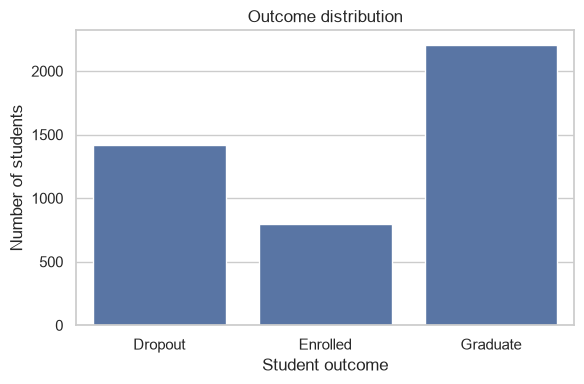

In [4]:
outcome_counts = student_records_table[OUTCOME_COLUMN_NAME].value_counts().reindex(OUTCOME_CLASS_NAMES)
outcome_share_percent = (outcome_counts / outcome_counts.sum() * 100).round(1)
print(pd.DataFrame({"students": outcome_counts, "share_percent": outcome_share_percent}).to_string())

figure, axis = plt.subplots(figsize=(6, 4))
sns.barplot(x=outcome_counts.index, y=outcome_counts.values, ax=axis)
axis.set_xlabel("Student outcome")
axis.set_ylabel("Number of students")
axis.set_title("Outcome distribution")
plt.tight_layout()
plt.show()

## 4. Which columns are really categories?

Many columns are stored as numbers but are actually category codes (for example *Course* or *Marital Status*). Counting the distinct values per column helps decide which ones need one-hot encoding and which are genuine numeric measurements.

In [5]:
distinct_values_per_feature = (
    student_records_table.drop(columns=[OUTCOME_COLUMN_NAME]).nunique().sort_values()
)
print(distinct_values_per_feature.to_string())

Daytime/evening attendance                          2
Displaced                                           2
Debtor                                              2
Educational special needs                           2
International                                       2
Scholarship holder                                  2
Gender                                              2
Tuition fees up to date                             2
Marital Status                                      6
Application order                                   8
Inflation rate                                      9
Curricular units 2nd sem (without evaluations)     10
GDP                                                10
Unemployment rate                                  10
Curricular units 1st sem (without evaluations)     11
Previous qualification                             17
Course                                             17
Application mode                                   18
Curricular units 2nd sem (cr

## 5. Academic grades by outcome

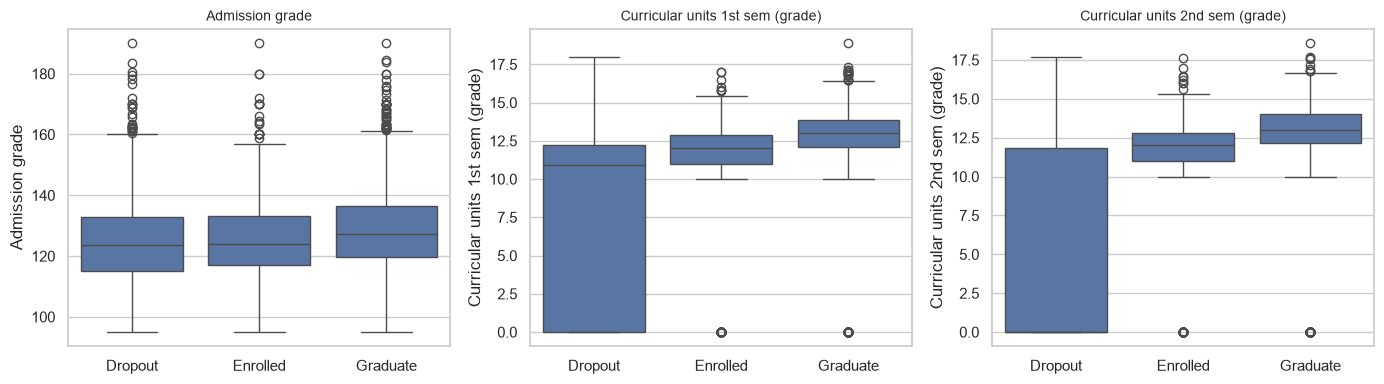

In [6]:
grade_columns_to_compare = [
    "Admission grade",
    "Curricular units 1st sem (grade)",
    "Curricular units 2nd sem (grade)",
]

figure, axes = plt.subplots(1, 3, figsize=(14, 4))
for axis, grade_column in zip(axes, grade_columns_to_compare):
    sns.boxplot(
        data=student_records_table,
        x=OUTCOME_COLUMN_NAME,
        y=grade_column,
        order=OUTCOME_CLASS_NAMES,
        ax=axis,
    )
    axis.set_title(grade_column, fontsize=10)
    axis.set_xlabel("")
plt.tight_layout()
plt.show()

## 6. Findings

- **Size:** 4,424 students and 36 input features, well above the assignment minimums of 500 rows and 12 features.
- **Quality:** no missing cells and no duplicated rows, so no imputation or row removal is needed.
- **Class balance:** Graduate 49.9%, Dropout 32.1%, Enrolled 17.9%. The classes are imbalanced, so plain accuracy can look good while the small Enrolled class is predicted badly. This is why macro-averaged precision, recall, F1 and AUC, together with MCC, are reported.
- **Feature types:** 29 columns are integers, 7 are decimals and the outcome is text. Many integer columns are category codes (Course has 17 values, Application mode 18, the parents' occupation and qualification columns 29 to 46). Treating these codes as plain numbers would imply a false order, so the nominal columns will be one-hot encoded and the genuine measurements will be scaled.
- **Signal in the grades:** the median second-semester grade is 0.0 for Dropout but 12.0 for Enrolled and 13.0 for Graduate. Median first-semester grades follow the same order (10.9, 12.0, 13.0). Early academic performance clearly separates the outcomes, so even simple models should do reasonably well.

## 7. Preparing the data for modelling

The records are split 80/20 into training and held-out test parts. The split is stratified, so each outcome keeps the same share in both parts, and it uses a fixed seed so it can be reproduced. The held-out part is saved as `test_data.csv` and is never used for training.

The preprocessing step (one-hot encoding of category codes, scaling of numeric measurements) is fitted on the training part only. Fitting it on all records would leak information from the test records into training.

In [7]:
records_split = build_data_split_service().split_records(student_records_table)
records_repository.save_held_out_records(records_split.held_out_records)

training_outcome_counts = records_split.training_records[OUTCOME_COLUMN_NAME].value_counts()
held_out_outcome_counts = records_split.held_out_records[OUTCOME_COLUMN_NAME].value_counts()
split_summary = pd.DataFrame(
    {
        "training_students": training_outcome_counts,
        "training_share_percent": (training_outcome_counts / training_outcome_counts.sum() * 100).round(1),
        "held_out_students": held_out_outcome_counts,
        "held_out_share_percent": (held_out_outcome_counts / held_out_outcome_counts.sum() * 100).round(1),
    }
).reindex(OUTCOME_CLASS_NAMES)

print(f"Training records: {len(records_split.training_records)}")
print(f"Held-out records: {len(records_split.held_out_records)}")
print()
print(split_summary.to_string())

Training records: 3539
Held-out records: 885

          training_students  training_share_percent  held_out_students  held_out_share_percent
Target                                                                                        
Dropout                1137                    32.1                284                    32.1
Enrolled                635                    17.9                159                    18.0
Graduate               1767                    49.9                442                    49.9


In [8]:
input_columns = STUDENT_FEATURE_CATALOG.input_columns(list(student_records_table.columns))
feature_transformer = build_feature_transformer_builder().build(input_columns)

# Fit on training records only, then reuse the fitted step on the held-out records.
training_features_encoded = feature_transformer.fit_transform(records_split.training_records[input_columns])
held_out_features_encoded = feature_transformer.transform(records_split.held_out_records[input_columns])

print(f"Input columns before encoding: {len(input_columns)}")
print(f"Columns after encoding: {training_features_encoded.shape[1]}")
print(f"Training matrix shape: {training_features_encoded.shape}")
print(f"Held-out matrix shape: {held_out_features_encoded.shape}")
print(f"Missing values after encoding: {int(np.isnan(training_features_encoded).sum() + np.isnan(held_out_features_encoded).sum())}")

# Confirm the exported file matches what was held out.
exported_test_data = pd.read_csv(HELD_OUT_TEST_DATA_FILE)
print(f"test_data.csv rows: {len(exported_test_data)}, columns: {exported_test_data.shape[1]}")
print(f"test_data.csv matches the held-out records: {exported_test_data.equals(records_split.held_out_records)}")

Input columns before encoding: 36
Columns after encoding: 236
Training matrix shape: (3539, 236)
Held-out matrix shape: (885, 236)
Missing values after encoding: 0
test_data.csv rows: 885, columns: 37
test_data.csv matches the held-out records: True


**Result of this step:** 3,539 training students and 885 held-out students, with almost identical outcome shares in both groups (Dropout 32.1%, Enrolled 17.9% to 18.0%, Graduate 49.9%). The 36 input columns become 236 numeric columns after one-hot encoding and scaling, with no missing values. The matrices above only illustrate the step. Each saved model carries its own preprocessing step, fitted on the training students only.

## 8. Training the five classifiers

This section trains and tunes all five classifiers on exactly the same training students, then saves them. The sub-sections are:

- **8.1** the five classifiers and why they were chosen
- **8.2** how each one is trained and tuned, with notes on the method
- **8.3** running the training
- **8.4** the hyperparameters that were searched and chosen
- **8.5** a worked example of how cross-validation picks a value
- **8.6** why Gaussian Naive Bayes needs a smoothing search

### 8.1 The five classifiers

| Classifier | Basic idea | Why it is included |
|---|---|---|
| **Logistic Regression** | Weighs every column and turns the weighted sum into a probability for each outcome | Simple, fast and a strong baseline once the columns are scaled |
| **Decision Tree** | Asks a chain of yes/no questions about the columns | Easy to follow and able to capture rules that are not straight lines |
| **K-Nearest Neighbors (kNN)** | Finds the most similar training students and lets them vote | Makes no assumption about the shape of the data |
| **Gaussian Naive Bayes** | Assumes the columns are independent within each outcome and multiplies their likelihoods | Very fast, and shows how far a strong simplifying assumption can go |
| **Support Vector Machine (SVM)** | Finds the boundary that separates the outcomes with the widest margin | Often strong on medium-sized tables of numbers |

### 8.2 How each classifier is trained and tuned

- **One pipeline per classifier.** Each saved model is a pipeline: the preprocessing step (one-hot encoding and scaling) followed by the classifier. It is fitted on the training students only, and the same preprocessing is applied automatically to any new students.
- **Tuning by cross-validation.** Each classifier chooses its own hyperparameters (settings fixed before training) by 5-fold stratified cross-validation, scored with macro F1, inside the training students only. Sub-section 8.5 explains the mechanics with a worked example. The held-out students never take part in this choice, so the scores in section 9 are an honest estimate.
- **Notes on the method**
  - *SVM probabilities.* An SVM does not give probabilities by itself, and the AUC needs them. The SVM is therefore wrapped in a sigmoid calibration step.
  - *Preprocessing and cross-validation.* The preprocessing is fitted once on all training students before the cross-validation, so each validation round slightly influences the scaling values. This affects only the cross-validation scores used to choose settings, never the held-out scores.
  - *No class balancing.* No class weights or resampling are used. The splits and cross-validation folds are stratified, which keeps the outcome shares equal in every part but does not change how the models learn.

In [9]:
from matplotlib.colors import LinearSegmentedColormap

# One fixed dark colour per classifier, reused in every chart so a model is easy to follow.
colour_of_classifier = {
    ClassifierKind.LOGISTIC_REGRESSION.display_name: "#1f4e9c",
    ClassifierKind.DECISION_TREE.display_name: "#b35a00",
    ClassifierKind.K_NEAREST_NEIGHBORS.display_name: "#1b7a3d",
    ClassifierKind.GAUSSIAN_NAIVE_BAYES.display_name: "#8e1b6b",
    ClassifierKind.SUPPORT_VECTOR_MACHINE.display_name: "#b01e1e",
}


def draw_table_as_image(table_frame, figure_width=15, wrap_widths=None, title=None):
    # Draw a small DataFrame as a banded table image (long text wraps inside its cell).
    wrap_widths = wrap_widths or {}
    column_names = list(table_frame.columns)
    header_cells = [textwrap.fill(str(name), wrap_widths.get(name, 24)) for name in column_names]
    body_rows = [
        [textwrap.fill(str(value), wrap_widths.get(name, 24)) for name, value in zip(column_names, row)]
        for row in table_frame.itertuples(index=False)
    ]

    # Each column is as wide as its longest line of text, and each row as tall as its tallest cell.
    longest_line_per_column = [
        max(len(line) for cell_text in [header_cells[position]] + [row[position] for row in body_rows] for line in cell_text.split("\n")) + 2
        for position in range(len(column_names))
    ]
    column_width_shares = [width / sum(longest_line_per_column) for width in longest_line_per_column]
    row_heights_in_inches = [
        0.30 * max(cell_text.count("\n") + 1 for cell_text in row) + 0.16 for row in [header_cells] + body_rows
    ]
    figure_height = sum(row_heights_in_inches) + (0.6 if title else 0.2)

    figure, axis = plt.subplots(figsize=(figure_width, figure_height))
    axis.axis("off")
    image_table = axis.table(
        cellText=body_rows, colLabels=header_cells, cellLoc="left", colLoc="left",
        loc="upper left", colWidths=column_width_shares,
    )
    image_table.auto_set_font_size(False)
    image_table.set_fontsize(10)
    for (row_position, _), table_cell in image_table.get_celld().items():
        table_cell.set_height(row_heights_in_inches[row_position] / figure_height)
        table_cell.set_edgecolor("#c9d3e3")
        if row_position == 0:
            table_cell.set_facecolor("#1f3b6d")
            table_cell.get_text().set_color("white")
            table_cell.get_text().set_fontweight("bold")
        elif row_position % 2 == 0:
            table_cell.set_facecolor("#eef2f9")
    if title:
        axis.set_title(title, fontsize=12, fontweight="bold", loc="left")
    plt.show()


### 8.3 Running the training

One training controller trains all five classifiers on the same training students. For each classifier it:

1. builds a pipeline made of the preprocessing step followed by the classifier,
2. fits the whole pipeline on the training students only (including the cross-validated search for settings),
3. predicts the held-out students and computes the six scores (Accuracy, AUC, Precision, Recall, F1, MCC),
4. saves the pipeline to the `model/` folder and the scores to `results/evaluation_results.csv`.

In [10]:
training_controller = build_training_controller()
training_results = training_controller.train_all_classifiers()

for training_result in training_results:
    status_text = "trained and saved" if training_result.succeeded else f"FAILED: {training_result.error_message}"
    print(f"{training_result.classifier_kind.display_name:<32} {status_text}")

# Stop the notebook here if any classifier failed, so later cells never use stale results.
assert all(training_result.succeeded for training_result in training_results), "See the messages above."


Logistic Regression              trained and saved
Decision Tree                    trained and saved
K-Nearest Neighbors (kNN)        trained and saved
Gaussian Naive Bayes             trained and saved
Support Vector Machine (SVM)     trained and saved


### 8.4 Hyperparameters searched and chosen

A hyperparameter is a setting that is fixed before training and controls how a model learns. Each classifier tried every combination in a small grid of values. Every combination was scored with 5-fold stratified cross-validation on the training students only (macro F1), and the best combination was refitted on all training students. The held-out students played no part in this choice.

The first table has one row per hyperparameter. Its last column flags a chosen value at the edge of the searched range, because a better value might lie beyond it. The second table counts the combinations and cross-validation fits for each model and shows the winning combination with its score.

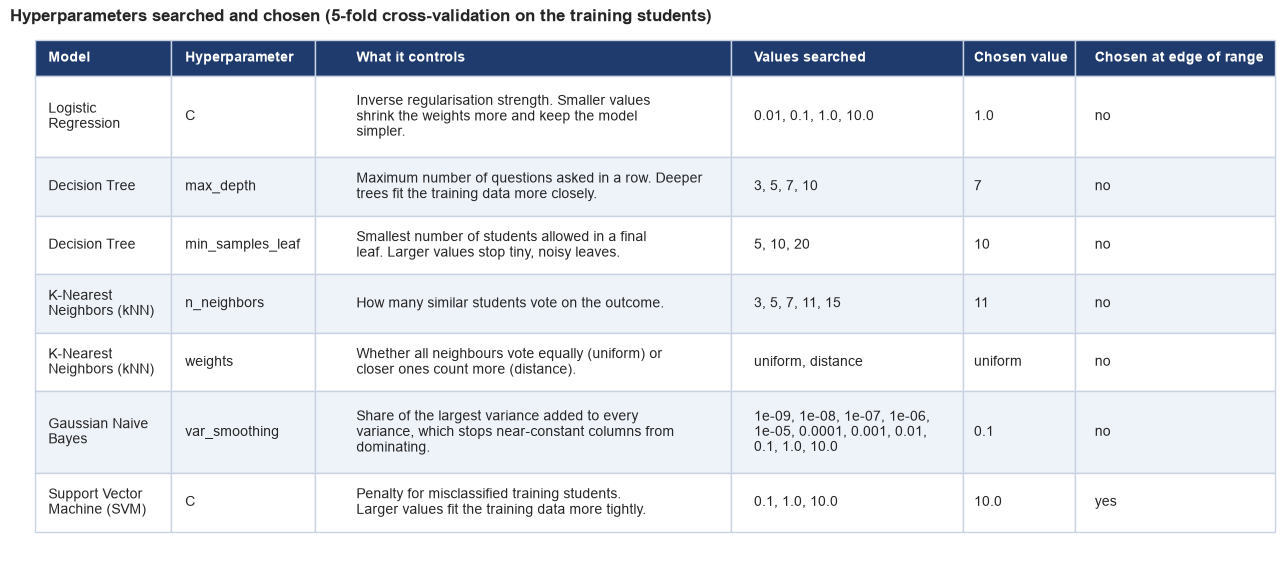

In [11]:
MEANING_OF_HYPERPARAMETER = {
    (ClassifierKind.LOGISTIC_REGRESSION, "C"): "Inverse regularisation strength. Smaller values shrink the weights more and keep the model simpler.",
    (ClassifierKind.DECISION_TREE, "max_depth"): "Maximum number of questions asked in a row. Deeper trees fit the training data more closely.",
    (ClassifierKind.DECISION_TREE, "min_samples_leaf"): "Smallest number of students allowed in a final leaf. Larger values stop tiny, noisy leaves.",
    (ClassifierKind.K_NEAREST_NEIGHBORS, "n_neighbors"): "How many similar students vote on the outcome.",
    (ClassifierKind.K_NEAREST_NEIGHBORS, "weights"): "Whether all neighbours vote equally (uniform) or closer ones count more (distance).",
    (ClassifierKind.GAUSSIAN_NAIVE_BAYES, "var_smoothing"): "Share of the largest variance added to every variance, which stops near-constant columns from dominating.",
    (ClassifierKind.SUPPORT_VECTOR_MACHINE, "C"): "Penalty for misclassified training students. Larger values fit the training data more tightly.",
}

model_repository = build_model_repository()

hyperparameter_rows = []
for classifier_kind in ClassifierKind.all_kinds():
    settings_search = model_repository.load_model(classifier_kind).named_steps["classifier"]
    for raw_name, searched_values in settings_search.param_grid.items():
        short_name = raw_name.replace("estimator__", "")  # the SVM is wrapped in a calibration step
        chosen_value = settings_search.best_params_[raw_name]
        is_number = all(isinstance(value, (int, float)) for value in searched_values)
        at_edge = is_number and chosen_value in (min(searched_values), max(searched_values))
        hyperparameter_rows.append(
            {
                "Model": classifier_kind.display_name,
                "Hyperparameter": short_name,
                "What it controls": MEANING_OF_HYPERPARAMETER[(classifier_kind, short_name)],
                "Values searched": ", ".join(str(value) for value in searched_values),
                "Chosen value": chosen_value,
                "Chosen at edge of range": "yes" if at_edge else "no",
            }
        )

draw_table_as_image(
    pd.DataFrame(hyperparameter_rows),
    figure_width=16,
    wrap_widths={"What it controls": 50, "Values searched": 30, "Model": 18},
    title="Hyperparameters searched and chosen (5-fold cross-validation on the training students)",
)


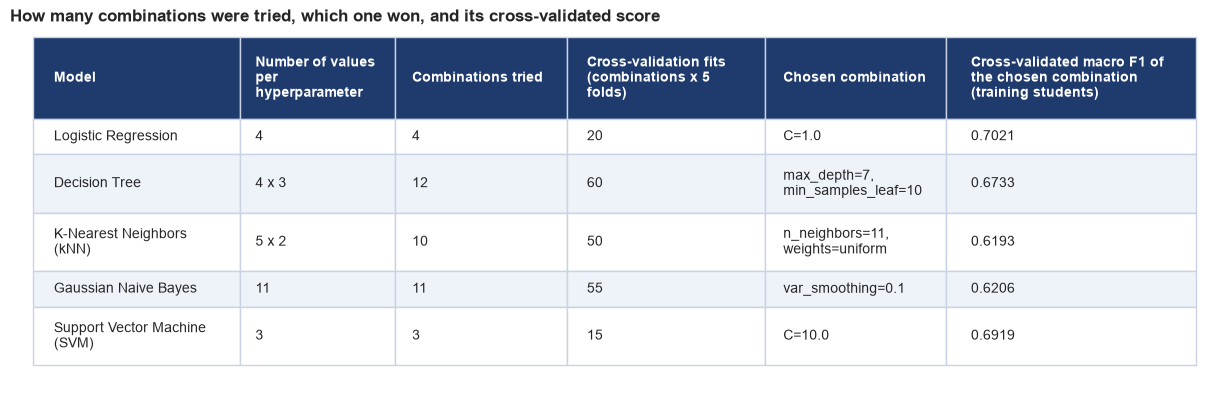

In [12]:
cross_validated_rows = []
for classifier_kind in ClassifierKind.all_kinds():
    settings_search = model_repository.load_model(classifier_kind).named_steps["classifier"]
    cross_validated_rows.append(
        {
            "Model": classifier_kind.display_name,
            "Number of values per hyperparameter": " x ".join(str(len(values)) for values in settings_search.param_grid.values()),
            "Combinations tried": len(settings_search.cv_results_["params"]),
            "Cross-validation fits (combinations x 5 folds)": len(settings_search.cv_results_["params"]) * settings_search.cv.get_n_splits(),
            # The SVM is wrapped in a calibration step, so its names start with "estimator__".
            "Chosen combination": ", ".join(
                f"{name.replace('estimator__', '')}={value}" for name, value in settings_search.best_params_.items()
            ),
            "Cross-validated macro F1 of the chosen combination (training students)": round(settings_search.best_score_, 4),
        }
    )
draw_table_as_image(
    pd.DataFrame(cross_validated_rows),
    figure_width=15,
    wrap_widths={
        "Number of values per hyperparameter": 16,
        "Cross-validation fits (combinations x 5 folds)": 22,
        "Chosen combination": 24,
        "Cross-validated macro F1 of the chosen combination (training students)": 28,
    },
    title="How many combinations were tried, which one won, and its cross-validated score",
)


### 8.5 How cross-validation picked the value, shown for Logistic Regression

Logistic Regression has one hyperparameter, `C`, with 4 candidate values, so there are 4 combinations. A candidate is a setting, not a single model: cross-validation trains it once per round, 5 times in total.

1. The 3,539 training students are split into 5 groups of about 708 (each group keeps the same Dropout, Enrolled and Graduate shares).
2. In each round, one group is held back for validation. The other 4 groups (about 2,831 students) are used to fit the model.
3. The fitted model predicts the validation group and its macro F1 is recorded.
4. After 5 rounds every student has been in the validation group exactly once, which gives 5 macro F1 values per candidate.

The mean of the 5 values is the candidate's cross-validated score, and the candidate with the highest mean is chosen. So 4 candidates x 5 rounds = 20 fits. After the choice, one last model is fitted with the chosen `C` on all 3,539 training students, and that is the saved model. The 20 round models are thrown away, and the held-out students are never touched.

Rows are the 4 candidate values of `C`. Columns are the 5 rounds, then the mean and the rank.

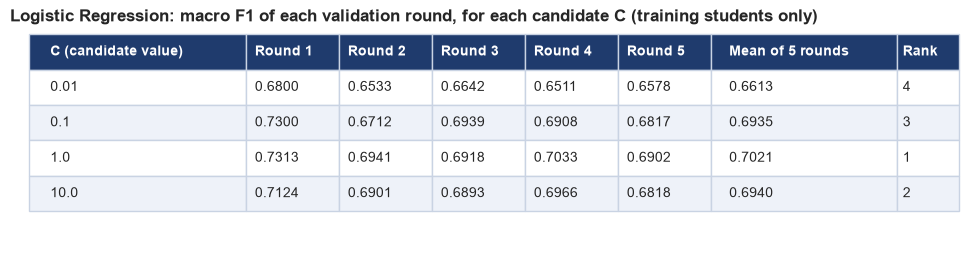

In [13]:
logistic_search = model_repository.load_model(ClassifierKind.LOGISTIC_REGRESSION).named_steps["classifier"]
search_results = logistic_search.cv_results_

per_round_scores = pd.DataFrame(
    {"C (candidate value)": [str(value) for value in search_results["param_C"]]}
)
for round_number in range(5):
    per_round_scores[f"Round {round_number + 1}"] = [f"{score:.4f}" for score in search_results[f"split{round_number}_test_score"]]
per_round_scores["Mean of 5 rounds"] = [f"{score:.4f}" for score in search_results["mean_test_score"]]
per_round_scores["Rank"] = [int(rank) for rank in search_results["rank_test_score"]]

draw_table_as_image(
    per_round_scores,
    figure_width=12,
    title="Logistic Regression: macro F1 of each validation round, for each candidate C (training students only)",
)


### 8.6 Why Gaussian Naive Bayes needs the smoothing search

`var_smoothing` is added to every variance. With the tiny default of 1e-9, a rare one-hot column has almost zero variance, so a single matching student gives an extreme likelihood and the model leans heavily to one class. The chart shows the cross-validated macro F1 for each value tried. The default 1e-9 is the leftmost point: it scores only 0.211, against 0.621 at the chosen value of 0.1.

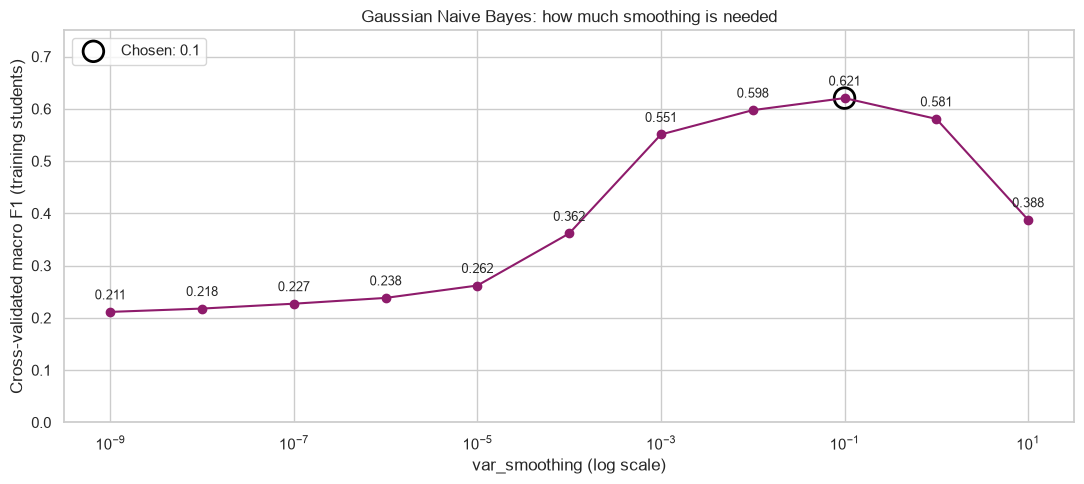

In [14]:
naive_bayes_search = model_repository.load_model(ClassifierKind.GAUSSIAN_NAIVE_BAYES).named_steps["classifier"]

smoothing_values = list(naive_bayes_search.cv_results_["param_var_smoothing"])
smoothing_scores = list(naive_bayes_search.cv_results_["mean_test_score"])
chosen_smoothing = naive_bayes_search.best_params_["var_smoothing"]
chosen_score = naive_bayes_search.best_score_

plt.figure(figsize=(11, 5))
plt.plot(smoothing_values, smoothing_scores, marker="o", color=colour_of_classifier[ClassifierKind.GAUSSIAN_NAIVE_BAYES.display_name])
for smoothing_value, smoothing_score in zip(smoothing_values, smoothing_scores):
    plt.annotate(f"{smoothing_score:.3f}", (smoothing_value, smoothing_score), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9)
plt.scatter([chosen_smoothing], [chosen_score], s=220, facecolors="none", edgecolors="black", linewidths=2, label=f"Chosen: {chosen_smoothing:g}")
plt.xscale("log")
plt.ylim(0, 0.75)
plt.xlabel("var_smoothing (log scale)")
plt.ylabel("Cross-validated macro F1 (training students)")
plt.title("Gaussian Naive Bayes: how much smoothing is needed")
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()


## 9. Comparing the five classifiers

Every value in this section is measured on the 885 held-out students (284 Dropout, 159 Enrolled, 442 Graduate), who played no part in training or tuning. The sub-sections are:

- **9.1** the six assignment metrics in one table
- **9.2** the same scores as charts, one panel per metric
- **9.3** confusion matrices, which show exactly which outcomes get mixed up
- **9.4** Precision, Recall, F1 and AUC for each outcome separately

### 9.1 Scores of the five classifiers

The table is read back from `results/evaluation_results.csv`, the single source of truth for the scores. Precision, Recall and F1 are macro averages, AUC is one-vs-rest averaged over the three outcomes, and MCC is the multi-class Matthews Correlation Coefficient.

**Why macro averages?** The assignment lists Precision, Recall and F1 without naming an averaging method, so this was a deliberate choice. Macro gives each of the three outcomes the same weight, however many students it has. Enrolled is the smallest group (about 18%) and the hardest to find, and it is also the group that most needs attention from the institution. A weighted average would let the large Graduate group dominate and would hide a weak Enrolled result. Macro also matches how the AUC is averaged (one-vs-rest, equal weight per outcome), so the table uses one consistent view. The Accuracy column is unaffected by this choice.

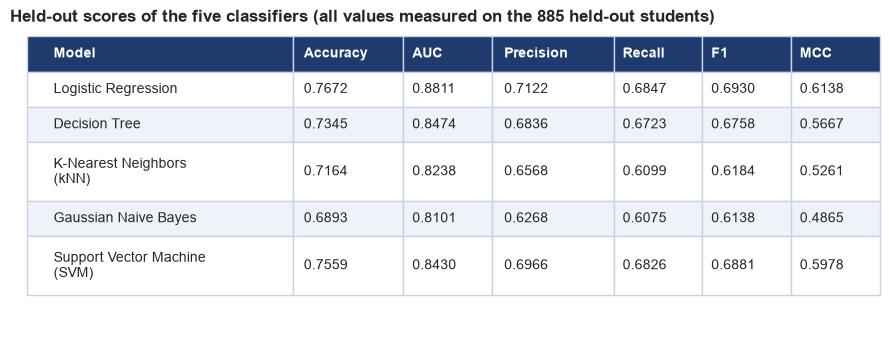

In [15]:
saved_scores_by_classifier = build_evaluation_results_repository().load_all_scores()

comparison_table = pd.DataFrame(
    {kind.display_name: scores.as_display_dict() for kind, scores in saved_scores_by_classifier.items()}
).T
comparison_table.index.name = "Model"
draw_table_as_image(
    comparison_table.reset_index().assign(**{name: comparison_table[name].map("{:.4f}".format).values for name in comparison_table.columns}),
    figure_width=11,
    title="Held-out scores of the five classifiers (all values measured on the 885 held-out students)",
)


### 9.2 Score comparison, one panel per metric

Each panel ranks the five classifiers on one metric, best on the left, with the exact score above every bar. Every classifier keeps the same dark colour in all charts of this notebook, and its name caption uses the same colour as its bar. The vertical axis of each panel is zoomed to the range of its own scores (it does not start at zero), so that gaps of a few hundredths stay visible. Read the labels for the true size of a gap.

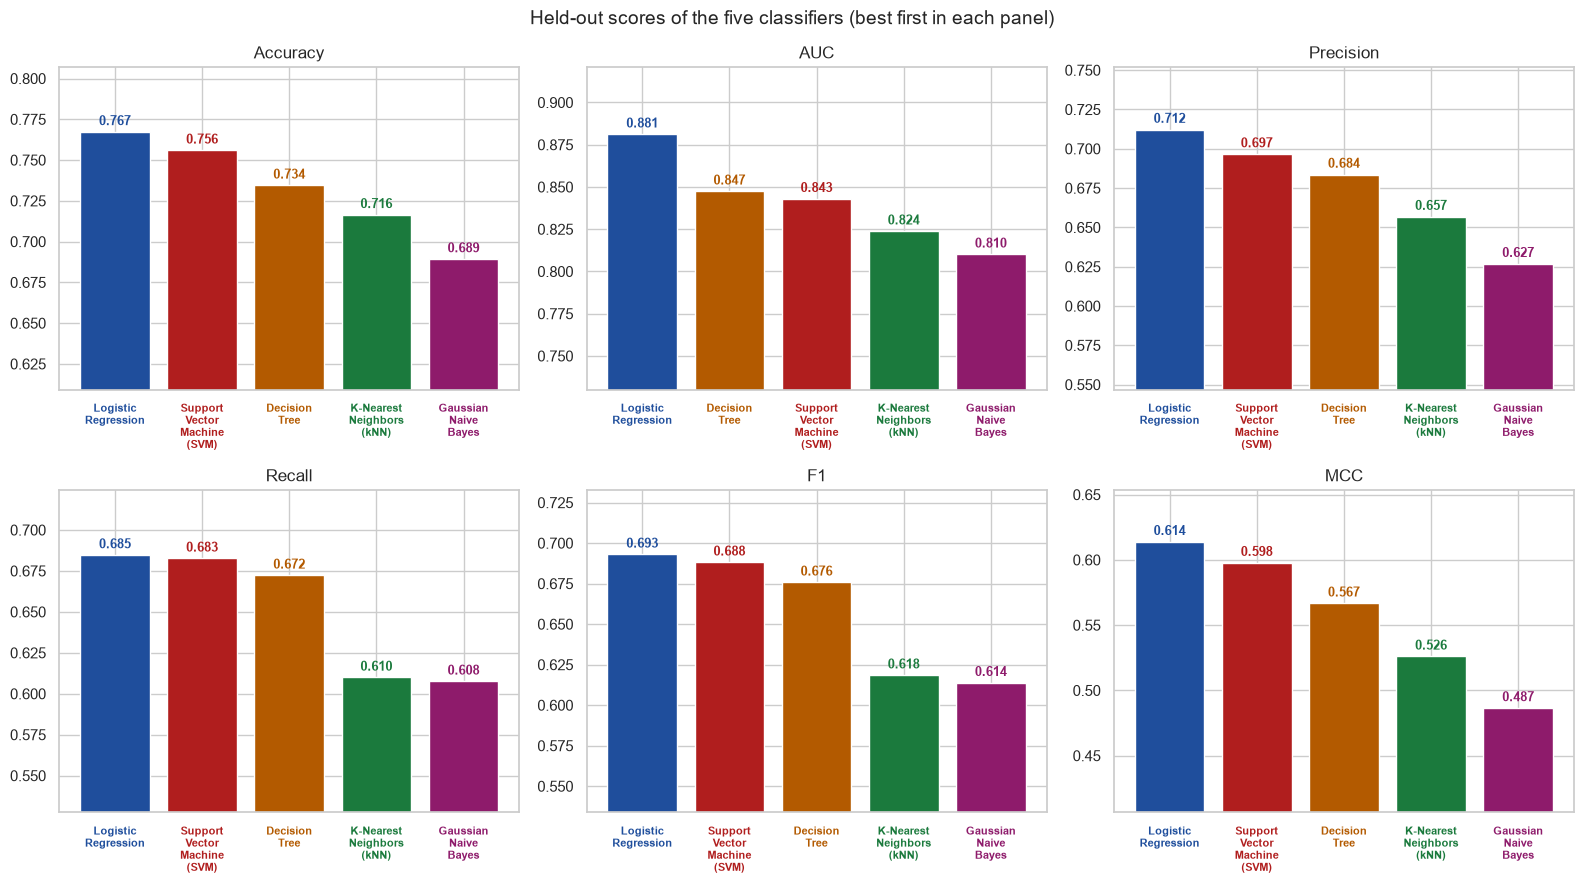

In [16]:
metric_names = list(comparison_table.columns)
figure, axes = plt.subplots(2, 3, figsize=(16, 9))

for axis, metric_name in zip(axes.ravel(), metric_names):
    ranked_scores = comparison_table[metric_name].sort_values(ascending=False)
    bar_colours = [colour_of_classifier[name] for name in ranked_scores.index]
    bars = axis.bar(range(len(ranked_scores)), ranked_scores.values, color=bar_colours)
    value_labels = axis.bar_label(bars, labels=[f"{score:.3f}" for score in ranked_scores.values], padding=3, fontsize=9, fontweight="bold")
    axis.set_xticks(range(len(ranked_scores)))
    caption_labels = axis.set_xticklabels([name.replace(" ", "\n") for name in ranked_scores.index], fontsize=8, fontweight="bold")
    for value_label, caption_label, name in zip(value_labels, caption_labels, ranked_scores.index):
        value_label.set_color(colour_of_classifier[name])
        caption_label.set_color(colour_of_classifier[name])
    axis.set_ylim(ranked_scores.min() - 0.08, ranked_scores.max() + 0.04)
    axis.set_title(metric_name, fontsize=12)

plt.suptitle("Held-out scores of the five classifiers (best first in each panel)", fontsize=14)
plt.tight_layout()
plt.show()


### 9.3 Confusion matrices: where each model makes its mistakes

A confusion matrix compares what each student actually did (rows, "Actual outcome") with what the model predicted (columns, "Predicted outcome"). The cells on the diagonal, outlined in black, are correct predictions. Every other cell is one specific kind of mistake, for example an Enrolled student predicted as Dropout.

**What the shades mean.** Each cell shows two numbers: the count of students, and that count as a percentage of all students whose actual outcome is that row, so every row adds up to 100%. The shade follows the percentage: the darker the cell, the larger the share of that actual outcome. A good model has dark diagonal cells and pale cells elsewhere. Percentages are used for the shading, and not raw counts, because Graduate has 442 students and Enrolled only 159, and raw counts would make the small group look pale even when it is predicted well. All five matrices use the same 0% to 100% shade scale, and each model keeps its own colour from the bar charts.

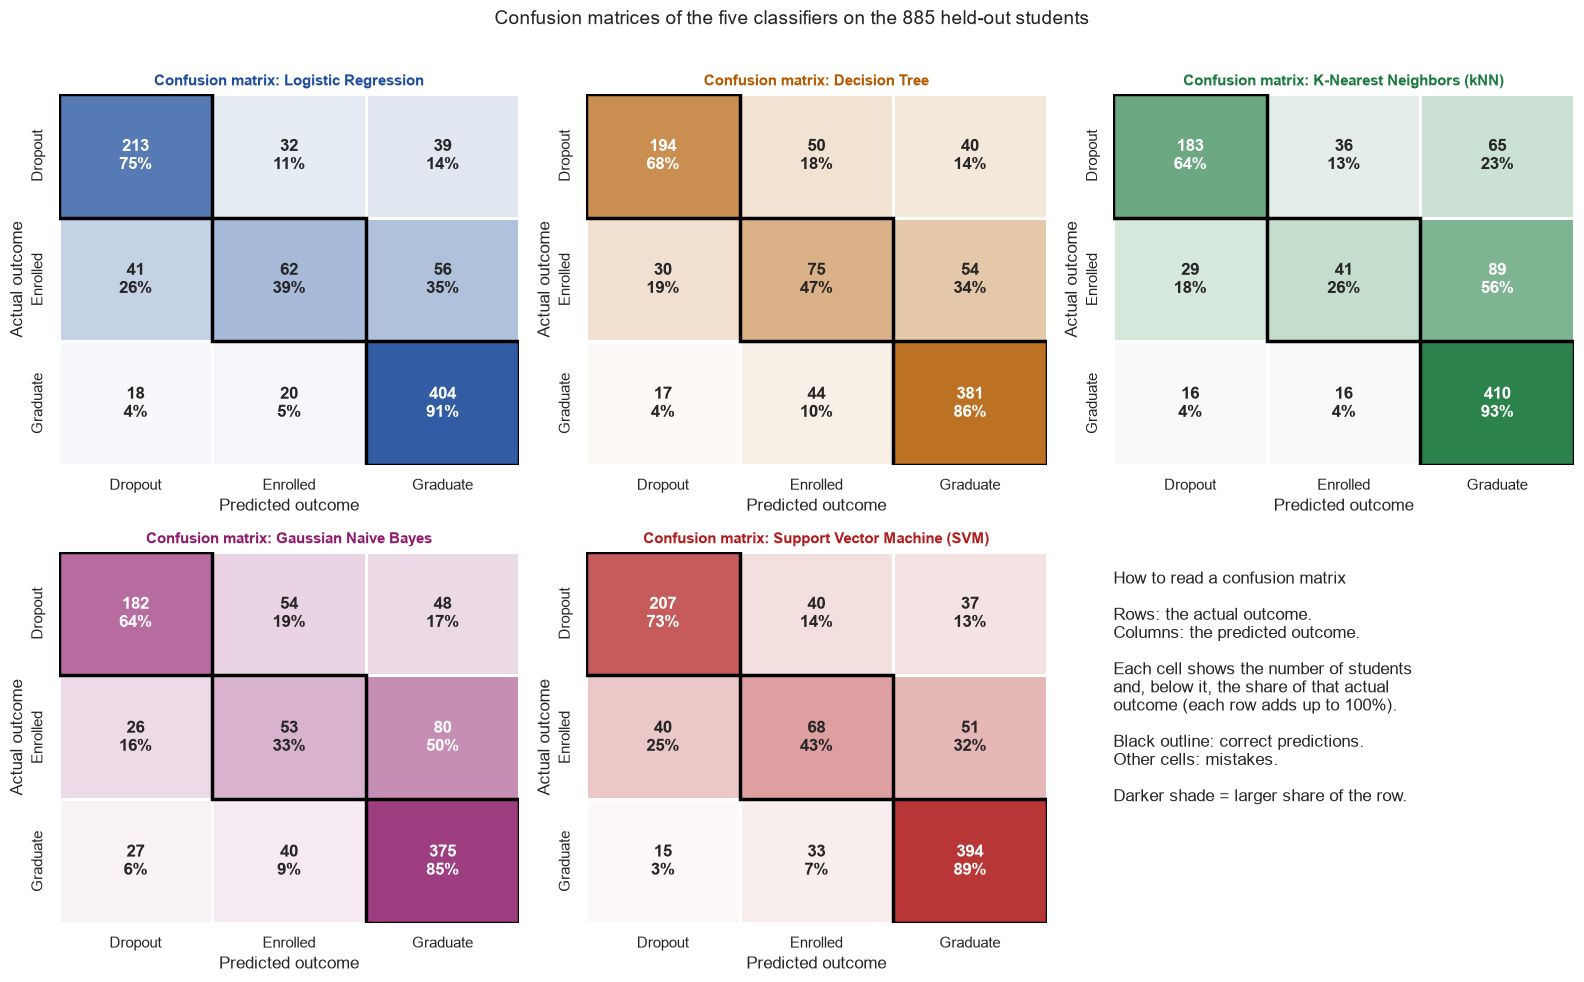

In [17]:
held_out_inputs = records_split.held_out_records[input_columns]
held_out_true_outcomes = records_split.held_out_records[OUTCOME_COLUMN_NAME]

figure, axes = plt.subplots(2, 3, figsize=(16, 10))
flat_axes = axes.ravel()
for axis, classifier_kind in zip(flat_axes, ClassifierKind.all_kinds()):
    model_name = classifier_kind.display_name
    model_colour = colour_of_classifier[model_name]
    white_to_model_colour = LinearSegmentedColormap.from_list("white_to_model_colour", ["#ffffff", model_colour])

    predicted_outcomes = model_repository.load_model(classifier_kind).predict(held_out_inputs)
    student_counts = confusion_matrix(held_out_true_outcomes, predicted_outcomes, labels=OUTCOME_CLASS_NAMES)
    share_of_actual_outcome = student_counts / student_counts.sum(axis=1, keepdims=True)
    cell_texts = np.array(
        [[f"{student_counts[row, column]}\n{share_of_actual_outcome[row, column]:.0%}" for column in range(3)] for row in range(3)]
    )

    sns.heatmap(
        share_of_actual_outcome, annot=cell_texts, fmt="", cmap=white_to_model_colour, vmin=0, vmax=1,
        xticklabels=OUTCOME_CLASS_NAMES, yticklabels=OUTCOME_CLASS_NAMES, cbar=False, ax=axis,
        linewidths=1, linecolor="white", annot_kws={"fontsize": 12, "fontweight": "bold"},
    )
    for diagonal_position in range(3):  # outline the correct predictions
        axis.add_patch(plt.Rectangle((diagonal_position, diagonal_position), 1, 1, fill=False, edgecolor="black", linewidth=2.5))
    axis.set_title(f"Confusion matrix: {model_name}", fontsize=11, fontweight="bold", color=model_colour)
    axis.set_xlabel("Predicted outcome")
    axis.set_ylabel("Actual outcome")

# The sixth panel explains how to read the other five.
reading_guide_axis = flat_axes[-1]
reading_guide_axis.axis("off")
reading_guide_axis.text(
    0.0, 0.95,
    "How to read a confusion matrix\n\n"
    "Rows: the actual outcome.\n"
    "Columns: the predicted outcome.\n\n"
    "Each cell shows the number of students\n"
    "and, below it, the share of that actual\n"
    "outcome (each row adds up to 100%).\n\n"
    "Black outline: correct predictions.\n"
    "Other cells: mistakes.\n\n"
    "Darker shade = larger share of the row.",
    va="top", ha="left", fontsize=12, transform=reading_guide_axis.transAxes,
)
plt.suptitle("Confusion matrices of the five classifiers on the 885 held-out students", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


### 9.4 Scores for each outcome separately

The table in 9.1 averages the three outcomes. These charts open it up. Precision, Recall and F1 are computed for each outcome on its own, and the AUC is the one-vs-rest AUC for that outcome. Accuracy and MCC describe all three outcomes together, so they have no per-outcome form and are not repeated here. The largest differences between the models are in the Enrolled group.

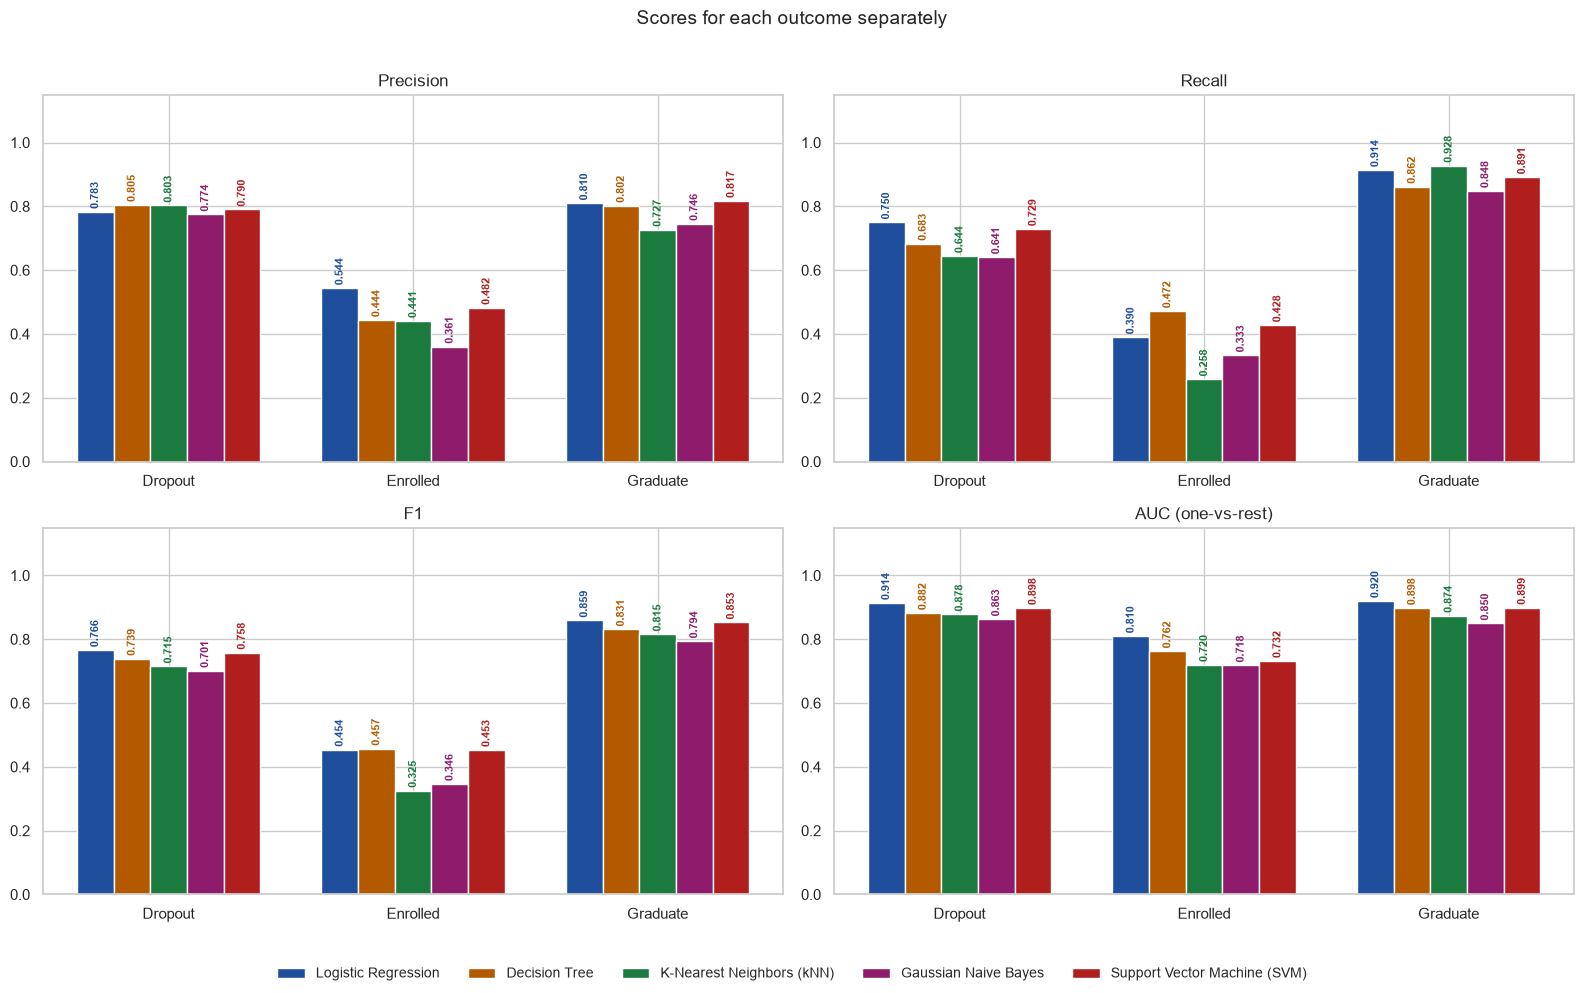

In [18]:
from sklearn.metrics import precision_recall_fscore_support, roc_auc_score

per_outcome_rows = []
for classifier_kind in ClassifierKind.all_kinds():
    saved_pipeline = model_repository.load_model(classifier_kind)
    predicted_outcomes = saved_pipeline.predict(held_out_inputs)
    outcome_probabilities = saved_pipeline.predict_proba(held_out_inputs)
    precisions, recalls, f1_scores, _ = precision_recall_fscore_support(
        held_out_true_outcomes, predicted_outcomes, labels=OUTCOME_CLASS_NAMES, zero_division=0
    )
    for position, outcome_name in enumerate(OUTCOME_CLASS_NAMES):
        # Probability columns follow the pipeline class order, which is the alphabetical outcome order.
        one_vs_rest_auc = roc_auc_score(held_out_true_outcomes == outcome_name, outcome_probabilities[:, position])
        per_outcome_rows.append(
            {
                "Model": classifier_kind.display_name,
                "Outcome": outcome_name,
                "Precision": precisions[position],
                "Recall": recalls[position],
                "F1": f1_scores[position],
                "AUC (one-vs-rest)": one_vs_rest_auc,
            }
        )

per_outcome_table = pd.DataFrame(per_outcome_rows).set_index(["Model", "Outcome"])

metric_names_per_outcome = ["Precision", "Recall", "F1", "AUC (one-vs-rest)"]
bar_width = 0.15
figure, axes = plt.subplots(2, 2, figsize=(16, 10))

for axis, metric_name in zip(axes.ravel(), metric_names_per_outcome):
    for model_position, classifier_kind in enumerate(ClassifierKind.all_kinds()):
        model_name = classifier_kind.display_name
        scores_per_outcome = [per_outcome_table.loc[(model_name, outcome_name), metric_name] for outcome_name in OUTCOME_CLASS_NAMES]
        bar_positions = [group_position + (model_position - 2) * bar_width for group_position in range(len(OUTCOME_CLASS_NAMES))]
        bars = axis.bar(bar_positions, scores_per_outcome, width=bar_width, color=colour_of_classifier[model_name], label=model_name)
        axis.bar_label(
            bars, labels=[f"{score:.3f}" for score in scores_per_outcome], padding=2, fontsize=8,
            rotation=90, color=colour_of_classifier[model_name], fontweight="bold",
        )
    axis.set_xticks(range(len(OUTCOME_CLASS_NAMES)))
    axis.set_xticklabels(OUTCOME_CLASS_NAMES, fontsize=11)
    axis.set_ylim(0, 1.15)
    axis.set_title(metric_name, fontsize=12)

legend_handles, legend_names = axes[0, 0].get_legend_handles_labels()
figure.legend(legend_handles, legend_names, loc="lower center", ncol=5, frameon=False, fontsize=10)
plt.suptitle("Scores for each outcome separately", fontsize=14)
plt.tight_layout(rect=[0, 0.05, 1, 0.97])
plt.show()


## 10. Observations

### 10.1 Findings for each model

All numbers below are measured on the 885 held-out students (284 Dropout, 159 Enrolled, 442 Graduate).

| Model | Observation |
|---|---|
| **Logistic Regression** | Best model on all six metrics (Accuracy 0.767, AUC 0.881, Precision 0.712, Recall 0.685, F1 0.693, MCC 0.614). It recognises Graduate (91% recall) and Dropout (75%) well. After scaling, the grades and other measurements relate to the outcome in a fairly straight-line way, which suits a linear model, and its regularisation keeps the 236 encoded columns from overfitting. |
| **Support Vector Machine** | Close second (Accuracy 0.756, F1 0.688, MCC 0.598). Logistic Regression is still ahead on all six overall metrics. SVM's one edge is on the Enrolled class alone (43% recall against 39% for Logistic Regression), but it is behind on Dropout and Graduate, and most clearly on AUC (0.843 against 0.881). The chosen C=10 is the largest value in the grid, so a still larger C might help slightly. |
| **Decision Tree** | Third on Accuracy (0.734), F1 (0.676) and MCC (0.567), and second on AUC (0.847). It has the best recall for the hardest outcome, Enrolled (47%), because its splits can isolate small groups. Its probabilities come from a few hard-edged splits, and Logistic Regression ranks students better (AUC 0.881). |
| **K-Nearest Neighbors** | Accuracy 0.716, but the lowest Enrolled recall (26%): it mostly votes for the large Graduate group, whose recall is the highest of all models (93%). With 236 columns, distances between students become similar, so the nearest neighbours are less informative. |
| **Gaussian Naive Bayes** | Last on Accuracy (0.689), F1 (0.614) and MCC (0.487). It assumes every column is independent of the others, which is false here (for example the first and second semester grades move together, and one-hot columns exclude each other). With its default smoothing (1e-9) it scored only 0.211 cross-validated macro F1 on the training students (see 8.6). Cross-validation chose var_smoothing = 0.1, which raised that score to 0.621. |

### 10.2 What the comparison shows

- **Winner:** Logistic Regression, with the best score on every metric. Its lead over the SVM is about one percentage point of accuracy, so on 885 students the two are close, but the ranking is the same for all six metrics, which makes the choice consistent.
- **The Enrolled outcome is hard for every model.** Enrolled recall is between 26% and 47% for all five models, against 64% to 75% for Dropout and 85% to 93% for Graduate. The confusion matrices in 9.3 show where those students go: they are mostly predicted as Graduate or Dropout. The Enrolled group is the smallest (17.9%) and sits between the other two, since those students have neither left nor finished. This is the reason accuracy alone would be misleading, and why macro-averaged scores and MCC are reported.
- **Tuning matters most for Gaussian Naive Bayes.** Its cross-validated macro F1 on the training students rose from 0.211 at the default smoothing to 0.621 at the chosen value (see 8.6).
- **Limits of this comparison:** the scores come from one 80/20 split, so differences of about one percentage point should not be over-read. The reasons given above for each model's behaviour are plausible explanations, not proven causes.

### 10.3 Summary and what comes next

- **Answer to the task:** a student's outcome can be predicted reasonably from the enrolment details and the first-year academic record. The best model, Logistic Regression, reaches 76.7% accuracy and an MCC of 0.614 on 885 students it has never seen.
- **Where the models struggle:** all five find Graduate and Dropout students much better than Enrolled students.
- **Fair comparison:** all five classifiers were trained on the same training students, tuned only by cross-validation inside them, and scored on the same held-out students.
- **What comes next:** the five saved models and the held-out file `test_data.csv` feed a Streamlit app. A user uploads the test CSV, picks a classifier, and sees the six metrics, the confusion matrix and the classification report without any retraining. The README reports the comparison table from 9.1.